# Cleaning up the data and Pre-Processing

## Import des librairie

In [67]:
import pandas as pd 
import matplotlib.pyplot as plt
import csv
import sklearn

## Chargement des données 

In [68]:
raw = pd.read_csv("Student_Dataset.csv", encoding="utf-8-sig", header=None, sep="\x00", engine="python", names=["line"])

df = raw["line"].str.extract(r'^(?P<ID>\d+),(?:(?P<Color>0x[0-9A-Fa-f]{6}),)?"?(?P<Testimony>.*?)"?$')

df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         1011 non-null   str  
 1   Color      614 non-null    str  
 2   Testimony  1011 non-null   str  
dtypes: str(3)
memory usage: 23.8 KB


,ID,Color,Testimony
count,1011,614,1011
unique,1011,1,1002
top,1,0x000000,"My calf became red, warm, and painful over a d..."
freq,1,614,2


Vérification des valeurs manquante du dataset:

In [69]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())
df = df.dropna(subset=["Testimony"])

Valeurs manquantes par colonne :
ID             0
Color        397
Testimony      0
dtype: int64


Vérification des doublons dans le dataset:

In [70]:
print(f"Nombre de doublons : {df.duplicated(subset=['Testimony']).sum()}")
df = df.drop_duplicates(subset=["Testimony"])

Nombre de doublons : 9


## Nettoyage du texte 

In [71]:
df["Testimony"] = df["Testimony"].str.strip()
df["Testimony"] = df["Testimony"].replace("", pd.NA)
df = df.dropna(subset=["Testimony"])

## Nettoyage plus poussé 

In [72]:
df["Testimony"] = df["Testimony"].str.replace("’", "'", regex=False)
df["Testimony"] = df["Testimony"].str.replace("‑", "-", regex=False)
df["Testimony"] = df["Testimony"].str.replace("—", "-", regex=False)

print("Apostrophes/tirets unicode restants :", df["Testimony"].str.contains("’|‑|—").sum())

Apostrophes/tirets unicode restants : 0


## Analyse des outliers

utilisation de la méthode IQR

count    1002.000000
mean       27.881238
std         5.661521
min        13.000000
25%        24.000000
50%        27.000000
75%        30.000000
max        55.000000
Name: n_words, dtype: float64


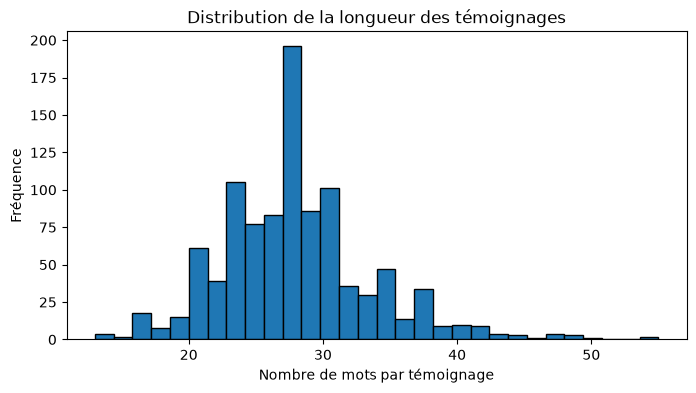

Borne IQR : [15, 39]mots
Nombre d'outliers détectés : 41 (4.1%)


,ID,n_words,Testimony
446,447,13,"My thirst level has increased, especially afte..."
473,474,13,"Before the rash, I had a deep aching sensation..."
679,680,14,My son touched the stove top while cooking; hi...
863,864,14,"I feel light-headed, especially when standing...."
353,354,40,It started with a scratchy throat and then set...
737,738,40,I noticed a rash on my hands after brushing my...
632,633,40,"After shaving my beard, a few tender bumps wit..."
88,89,40,"After shaving my beard, a few tender bumps wit..."
705,706,40,I notice my hair seems thinner and I have more...
762,763,40,I developed a rash on my upper back after taki...


In [73]:
df["n_words"] = df["Testimony"].str.split().str.len()

print(df["n_words"].describe())

plt.figure(figsize=(8,4))
plt.hist(df["n_words"], bins=30, edgecolor="black")
plt.xlabel("Nombre de mots par témoignage")
plt.ylabel("Fréquence")
plt.title("Distribution de la longueur des témoignages")
plt.show()

q1 = df["n_words"].quantile(0.25)
q3 = df["n_words"].quantile(0.75)
iqr = q3-q1
low_bound = q1 - 1.5 * iqr
high_bound = q3 + 1.5 * iqr

outliers = df[(df["n_words"] < low_bound) | (df["n_words"] > high_bound)]
print(f"Borne IQR : [{low_bound:.0f}, {high_bound:.0f}]mots")
print(f"Nombre d'outliers détectés : {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

outliers[["ID", "n_words", "Testimony"]].sort_values("n_words")

Conversion de l'ID en numérique

In [74]:
df["ID"] = pd.to_numeric(df["ID"], errors="coerce")

## Vérification de l'intégrité du parsing

In [75]:
with open("Student_Dataset.csv", encoding="utf-8-sig") as f:
    rows = list(csv.reader(f))

field_counts = {}
for r in rows:
    field_counts[len(r)] = field_counts.get(len(r), 0) + 1

print("Distribution du nombre de champs par ligne :", field_counts)
print(f"{field_counts.get(2, 0)} témoignages sans couleur assignée — "
      f"confirmé comme une caractéristique réelle du dataset, pas un bug de parsing.")

Distribution du nombre de champs par ligne : {2: 397, 3: 614}
397 témoignages sans couleur assignée — confirmé comme une caractéristique réelle du dataset, pas un bug de parsing.


## Vérification finale

In [76]:
print(df["Color"].value_counts(dropna=False))

df_clean = df.drop(columns=["n_words"]).copy()
print(df_clean.shape)

df_clean.to_csv("Student_Dataset_clean.csv", index=False)

Color
0x000000    606
NaN         396
Name: count, dtype: int64
(1002, 3)


# Training and Evaluation

## Vectorisation

In [77]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_df=0.9,
    min_df=2
)

X = vectorizer.fit_transform(df_clean["Testimony"])

print("Shape de la matrice TF-IDF :", X.shape)
print("Nombre de mots retenus (vocabulaire) :", len(vectorizer.get_feature_names_out()))
print("Exemples de mots :", list(vectorizer.get_feature_names_out())[:20])

Shape de la matrice TF-IDF : (1002, 1299)
Nombre de mots retenus (vocabulaire) : 1299
Exemples de mots : ['37', 'abdomen', 'able', 'accidentally', 'accompanied', 'ache', 'aches', 'aching', 'achy', 'active', 'activities', 'activity', 'actual', 'afternoon', 'afterward', 'aggravate', 'ago', 'ahead', 'air', 'allergic']


## Reduction de Dimension 

In [78]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=50, random_state=42)
X_reduced = svd.fit_transform(X)

print("Shape après réduction :", X_reduced.shape)
print("Variance expliquée cumulée :", svd.explained_variance_ratio_.sum())

Shape après réduction : (1002, 50)
Variance expliquée cumulée : 0.2651332945676505


### premier essai : n_components=50

un premier essaie avec  'n_components= 50' comme valeur abitraire , car j'ai  vue des sites et tutoriel qui l'utilise comme valuer par défault.
Elle donne une variable expliqué cumulée de seulement 26.5%. 

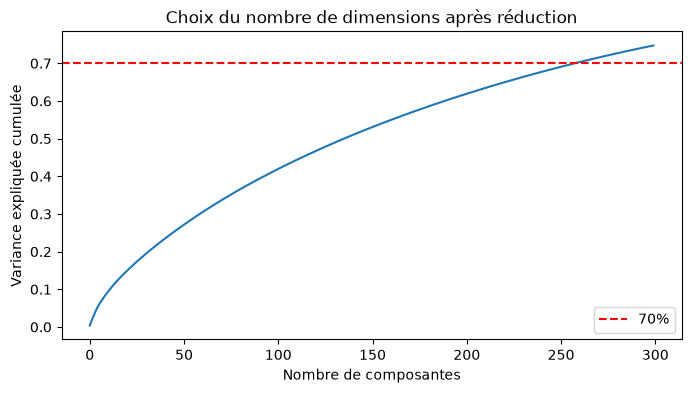

Nombre de composantes pour atteindre 70% de variance : 259


In [79]:
import numpy as np 

svd_test = TruncatedSVD(n_components=300, random_state=42)
svd_test.fit(X)

cumulative_variance = np.cumsum(svd_test.explained_variance_ratio_)

plt.figure(figsize=(8,4))
plt.plot(cumulative_variance)
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("Choix du nombre de dimensions après réduction")
plt.axhline(y=0.7, color="r", linestyle="--", label="70%")
plt.legend()
plt.show()

n_needed = np.argmax(cumulative_variance >= 0.7) + 1
print(f"Nombre de composantes pour atteindre 70% de variance : {n_needed}")

### Conclusion 

La courbe  de variance  cumulée  ne présente pas de coude net, la progression est régulière, sans palier marqué. Cela reflète la dispersion  naturelle du vocabulaire médical sur de nombreuses pathologies différentes : l'information n'est pas concentrée sur quelques dimensions dominantes. 

On retient donc **259 composantes**, valeur nécessaire pour atteindre 70% de variance expliquée — un seuil raisonnable pour conserver l'essentiel du signal sans revenir à la dimensionnalité complète 
(1299) du vocabulaire.

In [80]:
svd_final = TruncatedSVD(n_components=259, random_state=42)
X_reduced = svd_final.fit_transform(X)

print("Shape finale :", X_reduced.shape)
print("Variance expliquée cumulée :", svd_final.explained_variance_ratio_.sum())

Shape finale : (1002, 259)
Variance expliquée cumulée : 0.6986476432023114


## Clustering

### K-means

K-means nécessite de fixer `k` (le nombre de clusters) à l'avance. 
N'ayant pas de labels, on teste plusieurs valeurs de `k` et on compare via deux 
métriques : l'inertie (méthode du coude) et le silhouette score.

### Loss 

Contrairement à l'apprentissage supervisé, il n'y a pas de "loss" au 
sens classique ici, ni d'accuracy (pas de vraies étiquettes disponibles 
pour comparaison). K-means minimise cependant une quantité équivalente : 
l'**inertie**, la somme des distances au carré entre chaque point et le 
centre de son cluster. C'est cette valeur qui diminue à chaque itération 
de l'algorithme, jouant le rôle de fonction objectif à minimiser — 
visualisée dans la méthode du coude ci-dessous.

L'évaluation de la qualité du clustering se fait plutôt via le 
**silhouette score**, qui joue ici le rôle d'équivalent à l'accuracy : 
il mesure la qualité de la séparation des clusters sans nécessiter de 
labels.

In [81]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_reduced)
    results.append((k, km.inertia_, silhouette_score(X_reduced, labels)))

results_df = pd.DataFrame(results, columns=["k", "inertia", "silhouette"])
print(results_df)

     k     inertia  silhouette
0    2  672.685280    0.023403
1    3  663.152031    0.019494
2    4  654.624659    0.022358
3    5  647.004085    0.026048
4    6  640.623792    0.027895
5    7  635.232422    0.027866
6    8  629.114737    0.030338
7    9  624.912817    0.030674
8   10  619.970310    0.033160
9   11  617.056764    0.031406
10  12  611.114786    0.036212
11  13  610.046843    0.030549
12  14  606.542963    0.033891
13  15  601.358424    0.034821


La courbe d'inertie ci-dessous ne montre pas de coude net — la baisse 
reste régulière sur toute la plage de `k` testée.

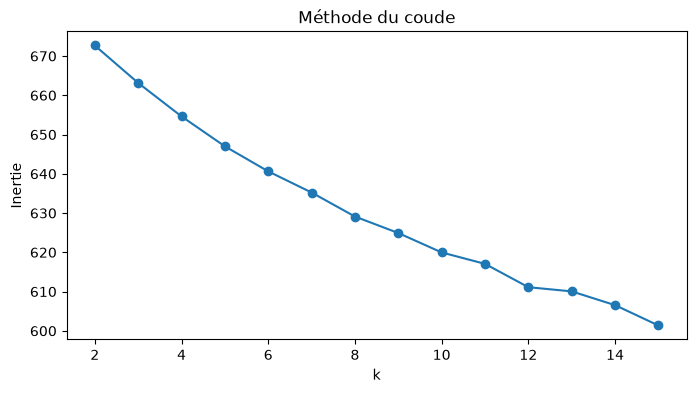

In [82]:
plt.figure(figsize=(8, 4))
plt.plot(results_df["k"], results_df["inertia"], marker="o")
plt.xlabel("k")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.show()

Le silhouette score reste très faible (0.02 à 0.04) quel que soit `k`, 
sans pic distinct — signe que K-means ne parvient pas à séparer des 
clusters nets dans cet espace à 259 dimensions.

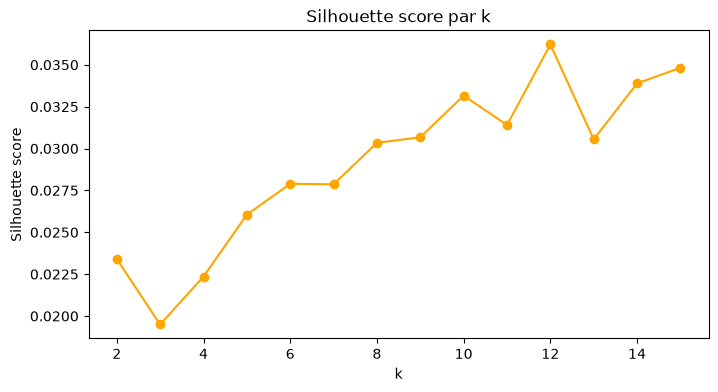

In [83]:
plt.figure(figsize=(8, 4))
plt.plot(results_df["k"], results_df["silhouette"], marker="o", color="orange")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette score par k")
plt.show()

### Échec de K-means

Aucune valeur de `k` ne se détache : ni coude marqué sur l'inertie, ni 
pic net sur le silhouette score. Ceci suggère que le fléau de la 
dimensionnalité (259 composantes) empêche K-means de bien discriminer 
les groupes. On teste un algorithme basé sur la densité en comparaison.

### DBSCAN

DBSCAN ne nécessite pas de fixer le nombre de clusters à l'avance — il 
identifie des zones denses de points, séparées par des zones creuses 
(bruit). Deux paramètres à régler : `eps` (distance maximale entre 
voisins) et `min_samples` (nombre minimum de voisins pour former une 
zone dense).

On détermine `eps` via la distance de chaque point à son 5e plus proche 
voisin — `eps` doit se situer là où cette distance augmente nettement.

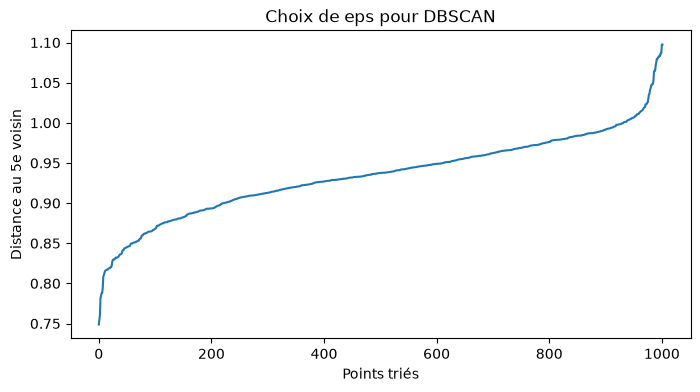

In [84]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
distances, _ = neighbors.fit(X_reduced).kneighbors(X_reduced)
distances = np.sort(distances[:, 4])

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.xlabel("Points triés")
plt.ylabel("Distance au 5e voisin")
plt.title("Choix de eps pour DBSCAN")
plt.show()

La courbe est très plate — les distances au 5e voisin sont concentrées 
entre 0.93 et 1.08 pour la quasi-totalité des points, sans rupture nette. 
On teste tout de même plusieurs valeurs de `eps` autour de cette plage.

In [85]:
for eps in [0.3, 0.5, 0.7, 1.0, 1.2]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_reduced)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"eps={eps}: clusters={n_clusters}, bruit={n_noise} ({n_noise/len(labels)*100:.1f}%)")

eps=0.3: clusters=0, bruit=1002 (100.0%)
eps=0.5: clusters=0, bruit=1002 (100.0%)
eps=0.7: clusters=0, bruit=1002 (100.0%)
eps=1.0: clusters=1, bruit=12 (1.2%)
eps=1.2: clusters=1, bruit=0 (0.0%)


### Échec de DBSCAN

Aucune valeur de `eps` intermédiaire ne produit plusieurs clusters 
distincts : en dessous de ~1.0, tous les points sont classés bruit 
(rien n'est assez dense) ; au-dessus, tous les points fusionnent en un 
seul cluster géant. Ce résultat confirme, avec K-means, que le fléau de 
la dimensionnalité (259 composantes) empêche toute séparation nette 
dans cet espace.

## Nouvel essai : réduction de dimension plus poussé

Les deux algorithmes testés échouent en raison du fléau de la 
dimensionnalité (259 composantes). On teste une réduction plus forte 
(30 composantes) pour voir si une structure de distance plus exploitable 
émerge, au prix d'une variance expliquée plus faible.

In [86]:
svd_test = TruncatedSVD(n_components=30, random_state=42)
X_test = svd_test.fit_transform(X)
print("Variance expliquée :", svd_test.explained_variance_ratio_.sum())

results_30 = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_test)
    results_30.append((k, km.inertia_, silhouette_score(X_test, labels)))

results_30_df = pd.DataFrame(results_30, columns=["k", "inertia", "silhouette"])
print(results_30_df)

Variance expliquée : 0.18916084660339838
     k     inertia  silhouette
0    2  174.183244    0.150351
1    3  165.168492    0.064721
2    4  156.817050    0.070209
3    5  148.729116    0.086381
4    6  143.514512    0.081985
5    7  138.400612    0.110708
6    8  133.594165    0.095638
7    9  126.848289    0.113468
8   10  122.374552    0.126699
9   11  119.379560    0.126590
10  12  116.867174    0.121917
11  13  112.235188    0.120414
12  14  108.972337    0.125239
13  15  107.108656    0.130688


### Inspection du clustering à k=2

Le meilleur score silhouette (0.150) est obtenu pour k=2. On inspecte 
le contenu des deux clusters pour vérifier si cette séparation fait 
sens médicalement.

In [87]:
km_final = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_final = km_final.fit_predict(X_test)

df_clean["cluster"] = labels_final
print(df_clean["cluster"].value_counts())

print("\n--- Exemples cluster 0 ---")
print(df_clean[df_clean["cluster"] == 0]["Testimony"].head(5).to_string())

print("\n--- Exemples cluster 1 ---")
print(df_clean[df_clean["cluster"] == 1]["Testimony"].head(5).to_string())

cluster
1    866
0    136
Name: count, dtype: int64

--- Exemples cluster 0 ---
19    I woke up with a runny nose and a sore throat,...
20    Since last week, my right ear has been aching ...
24    My right ear hurts like a stone in the middle....
25    My right ear hurts when I swallow, and I feel ...
30    I had a light headache and a runny nose after ...

--- Exemples cluster 1 ---
0    On uneven paths the heel feels wobbly side-to-...
1    The feverish feeling eased, but I'm now breath...
2    While working in the garden, I touched a metal...
3    A short sprint brought on a twinge in the midd...
4    I accidentally left my hand on a hot mug for a...


### Interprétation

Le cluster 0 (136 témoignages) regroupe de façon cohérente des symptômes 
ORL / rhume (nez qui coule, mal de gorge, douleur à l'oreille) — un vrai 
pattern médical reconnaissable. Le cluster 1 (866 témoignages) est en 
revanche hétérogène : blessures, troubles respiratoires, douleurs 
musculaires s'y retrouvent mélangés. K-means a donc isolé un signal 
textuel fort (vocabulaire ORL) sans réussir à segmenter finement le 
reste des pathologies avec seulement k=2.

Une piste naturelle serait d'augmenter k pour affiner le cluster 1 en 
sous-catégories plus homogènes.

## Visualisation

On projette les données en 2D pour la visualisation (via `TruncatedSVD`), 
et on colore chaque point selon la colonne `Color` du dataset, comme 
demandé. Note : cette projection 2D ne capture qu'une fraction de la 
variance totale (~1.7%), donc elle est une simplification — la vraie 
séparation des clusters a été calculée en 30 dimensions.

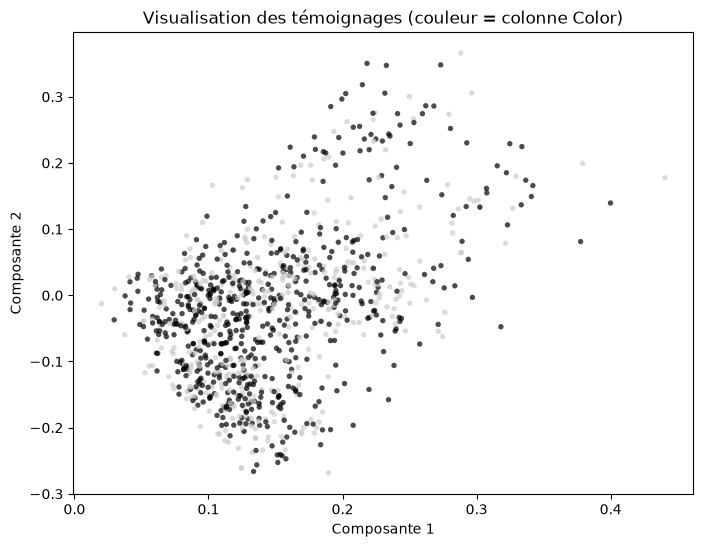

In [88]:
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X)

color_map = df_clean["Color"].fillna("0xCCCCCC").apply(
    lambda c: "#" + c.replace("0x", "")
)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=color_map, s=15, alpha=0.7, edgecolors="none")
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.title("Visualisation des témoignages (couleur = colonne Color)")
plt.show()

On superpose ensuite les clusters trouvés par K-means (k=2, sur l'espace 
à 30 dimensions) pour comparer visuellement la structure des données 
avec l'assignation de clusters.

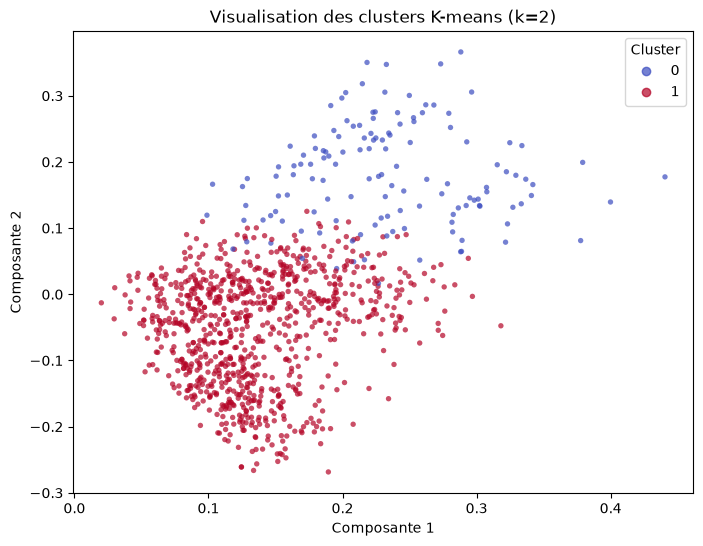

In [89]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_clean["cluster"], 
                       cmap="coolwarm", s=15, alpha=0.7, edgecolors="none")
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.title("Visualisation des clusters K-means (k=2)")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()